In [82]:
# RAW DATA
#    │
#    ▼
# DATA QUALITY AUDIT
#    │
#    ▼
# CLEANING
#    │
#    ├── Missing values
#    ├── Duplicates
#    ├── Wrong data types
#    ├── Inconsistent categories
#    ├── Currency / percentage parsing
#    └── Outliers
#    │
#    ▼
# FEATURE ENGINEERING
#    │
#    ├── Time features
#    ├── Revenue features
#    ├── Profitability features
#    ├── Customer features
#    ├── Product features
#    ├── Operational features
#    └── RFM
#    │
#    ▼
# EDA
#    │
#    ├── Sales
#    ├── Profit
#    ├── Customers
#    ├── Products
#    ├── Regions
#    └── Channels
#    │
#    ▼
# STATISTICAL ANALYSIS
#    │
#    ├── Correlation
#    ├── Hypothesis testing
#    └── Relationship analysis
#    │
#    ▼
# PREDICTIVE ANALYTICS
#    │
#    └── Sales prediction
#    │
#    ▼
# POWER BI
#    │
#    └── Interactive business dashboard

| Category    | Examples                                                  |
| ----------- | --------------------------------------------------------- |
| Identifiers | `Invoice_ID`, `Customer_ID`                               |
| Date        | `Transaction_Date`                                        |
| Geography   | `Region`, `City`                                          |
| Customer    | `Customer_Type`, `Customer_Age`, `Customer_Tenure_Months` |
| Product     | `Product_Category`                                        |
| Sales       | `Units_Sold`, `Unit_Price`, `Gross_Sales`, `End_Sales`    |
| Discount    | `Discount`, `Discount_Amount`                             |
| Profit      | `Cost_of_Goods`, `Gross_Profit`, `Profit_Margin_Pct`      |
| Operations  | `Shipping_Cost`, `Delivery_Days`, `Returns_Count`         |
| Payment     | `Payment_Method`, `Late_Payment`                          |


In [83]:
import pandas as pd

df=pd.read_csv("/content/financial_sales_10000_dirty.csv")
df.head()

,Invoice_ID,Transaction_Date,Customer_ID,Region,City,Sales_Channel,Customer_Type,Product_Category,Payment_Method,Salesperson_ID,...,Gross_Profit,Profit_Margin_Pct,Customer_Age,Customer_Tenure_Months,Orders_Last_90_Days,Returns_Count,Delivery_Days,Customer_Rating,Late_Payment,End_Sales
0,INV-2025-009255,13-04-2025,CUST-01544,South,Chennai,Retail Store,Returning,Furniture,UPI,SP_047,...,716.63,23.59,44.0,32.0,3,0,3.2,2.9,No,3117.38
1,INV-2025-002985,24-04-2025,CUST-03307,North,Chandigarh,Online,Returning,Accessories,UPI,SP_008,...,3153.52,47.84,38.0,30.0,2,0,3.8,3.2,No,7991.26
2,INV-2025-004226,16-10-2025,CUST-01389,South,Kochi,Corporate,Returning,Furniture,UPI,SP_015,...,1888.78,23.06,46.0,8.0,1,1,3.0,3.8,No,8330.68
3,INV-2025-000591,11-08-2025,CUST-02724,Northeast,Imphal,Distributor,VIP,Electronics,Net Banking,SP_040,...,2868.46,16.55,46.0,3.0,2,0,6.4,3.8,No,20746.18
4,INV-2025-003939,28-08-2025,CUST-01204,Central,Raipur,Distributor,New,Furniture,Net Banking,SP_013,...,5390.18,12.89,18.0,12.0,1,1,2.5,3.9,No,49437.36


In [84]:
df.isnull().sum()

,0
Invoice_ID,0
Transaction_Date,0
Customer_ID,0
Region,120
City,35
Sales_Channel,0
Customer_Type,0
Product_Category,0
Payment_Method,90
Salesperson_ID,40


##PRINT THE COLUMNS WITH ONLY THE NULL VALUES

In [85]:
missing=df.loc[:,df.isnull().any()]
missing.isnull().sum()

,0
Region,120
City,35
Payment_Method,90
Salesperson_ID,40
Shipping_Cost,60
Customer_Age,75
Customer_Tenure_Months,91
Delivery_Days,55
Customer_Rating,110


In [86]:

print("Shape:", df.shape)

print("\n--- DATA TYPES ---")
print(df.dtypes)

print("\n--- MISSING VALUES ---")
print(df.isna().sum())

print("\n--- DUPLICATES ---")
print(df.duplicated().sum())

print("\n--- UNIQUE VALUES ---")
print(df.nunique())

print("\n--- NUMERICAL SUMMARY ---")
print(df.describe())

Shape: (10025, 31)

--- DATA TYPES ---
Invoice_ID                 object
Transaction_Date           object
Customer_ID                object
Region                     object
City                       object
Sales_Channel              object
Customer_Type              object
Product_Category           object
Payment_Method             object
Salesperson_ID             object
Units_Sold                  int64
Unit_Price                 object
Discount                   object
Shipping_Cost             float64
Tax_Rate                    int64
Gross_Sales               float64
Discount_Amount           float64
Net_Sales_Before_Tax      float64
Tax_Amount                float64
Total_Invoice_Value       float64
Cost_of_Goods             float64
Gross_Profit              float64
Profit_Margin_Pct         float64
Customer_Age              float64
Customer_Tenure_Months    float64
Orders_Last_90_Days         int64
Returns_Count               int64
Delivery_Days             float64
Customer_

#DATA CLEANING

In [87]:
clean=df.copy()

In [88]:
#measure number of duplicate rows
clean.duplicated().sum()


np.int64(25)

In [89]:
clean = clean.drop_duplicates()
clean.shape

(10000, 31)

In [90]:
print(clean["Transaction_Date"].dtype)

object


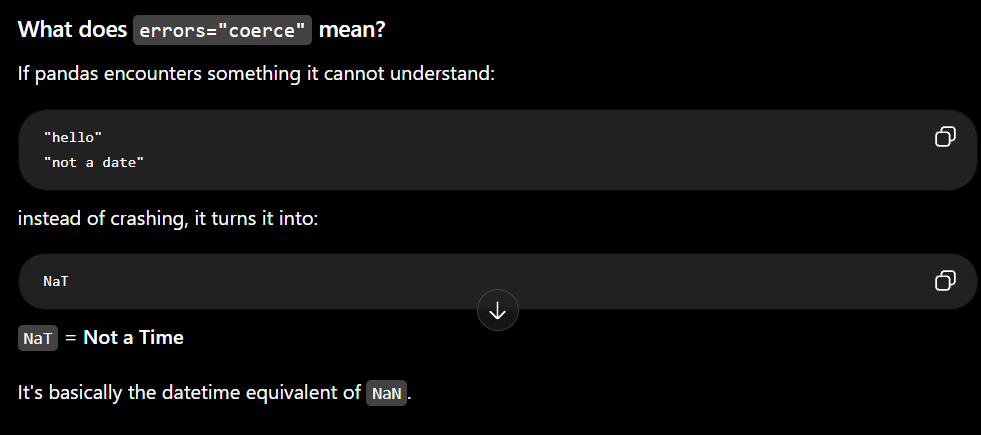

In [91]:
clean["Transaction_Date"] = pd.to_datetime(
    clean["Transaction_Date"],
    errors="coerce",
    dayfirst=True
)
print(clean["Transaction_Date"].dtype)

datetime64[ns]


In [92]:
print(clean["Transaction_Date"].min())
print(clean["Transaction_Date"].max())
clean["Transaction_Date"]

2025-01-01 00:00:00
2025-12-31 00:00:00


,Transaction_Date
0,2025-04-13
1,2025-04-24
2,2025-10-16
3,2025-08-11
4,2025-08-28
...,...
10020,2025-06-08
10021,2025-02-19
10022,2025-11-13
10023,2025-10-29


In [93]:
clean["Unit_Price"] = (
    clean["Unit_Price"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
)

In [94]:
clean["Unit_Price"] = pd.to_numeric(
    clean["Unit_Price"],
    errors="coerce"
)
print(clean["Unit_Price"].dtype)
print(clean["Unit_Price"].isna().sum())

float64
0


In [95]:
df.Discount

,Discount
0,10.56
1,2.97
2,9.49
3,1.1
4,9.02
...,...
10020,5.85
10021,4.16
10022,12.33
10023,3.05%


In [96]:
clean['Discount']=clean.Discount.astype(str).str.replace('%','')
clean['Discount']=pd.to_numeric(clean.Discount,errors="coerce")
clean.Discount

,Discount
0,10.56
1,2.97
2,9.49
3,1.10
4,9.02
...,...
10020,5.85
10021,4.16
10022,12.33
10023,3.05


In [97]:
print(clean["Discount"].describe())

count    10000.000000
mean         7.514267
std          4.618206
min          0.060000
25%          3.970000
50%          6.730000
75%         10.270000
max         29.670000
Name: Discount, dtype: float64


In [98]:
clean["Units_Sold"] = pd.to_numeric(
    clean["Units_Sold"],
    errors="coerce"
)
print(clean["Units_Sold"].dtype)
print(clean["Units_Sold"].isna().sum())

int64
0


In [99]:
clean["Sales_Channel"].unique()

array(['Retail Store', 'Online', 'Corporate', 'Distributor',
       'Marketplace', 'online', ' ONLINE '], dtype=object)

In [100]:
clean["Sales_Channel"] = (
    clean["Sales_Channel"]
    .astype("string")
    .str.strip()
)
clean["Sales_Channel"] = (
    clean["Sales_Channel"]
    .str.title()
)
print(clean["Sales_Channel"].value_counts(dropna=False))

Sales_Channel
Online          2843
Retail Store    2711
Distributor     2001
Marketplace     1263
Corporate       1182
Name: count, dtype: Int64


In [101]:
categorical_columns = [
    "Region",
    "City",
    "Customer_Type",
    "Product_Category",
    "Payment_Method",
    "Late_Payment"
]

for col in categorical_columns:
    clean[col] = (
        clean[col]
        .astype("string")
        .str.strip()
        .str.title()
    )
for col in categorical_columns:
    print("\n", col)
    print(clean[col].value_counts(dropna=False))


 Region
Region
South        1992
North        1762
East         1752
West         1748
Central      1453
Northeast    1173
<NA>          120
Name: count, dtype: Int64

 City
City
Bengaluru      522
Kochi          504
Hyderabad      503
Chennai        476
Delhi          475
Ranchi         460
Ahmedabad      456
Chandigarh     452
Mumbai         450
Patna          449
Pune           436
Kolkata        436
Lucknow        434
Bhubaneswar    425
Surat          420
Jaipur         420
Raipur         395
Bhopal         366
Nagpur         353
Indore         349
Imphal         328
Shillong       301
Guwahati       285
Agartala       270
<NA>            35
Name: count, dtype: Int64

 Customer_Type
Customer_Type
Returning    4181
New          3443
Vip          1379
Corporate     997
Name: count, dtype: Int64

 Product_Category
Product_Category
Electronics        2228
Clothing           1936
Home Appliances    1627
Furniture          1534
Office Supplies    1466
Accessories        1209
Name: count

In [102]:
numeric_impute = [
    "Customer_Age",
    "Customer_Tenure_Months",
    "Customer_Rating",
    "Shipping_Cost",
    "Delivery_Days"
]

for col in numeric_impute:
    clean[col] = clean[col].fillna(clean[col].median())

In [103]:
missing=clean.isna().sum()
print(missing[missing>0].sort_values(ascending=False))

Transaction_Date    120
Region              120
Payment_Method       90
Salesperson_ID       40
City                 35
dtype: int64


In [104]:
clean["Payment_Method"] = clean["Payment_Method"].fillna(
    "Unknown"
)
clean["Salesperson_ID"] = clean["Salesperson_ID"].fillna(
    "Unknown"
)
# This preserves the information:

# "We don't know this."

# rather than pretending:

# "We know it was UPI."


In [105]:
clean["City"] = clean["City"].fillna("Unknown")
# lets do it later for now fill NA s with unknown

# SEARCH FOR impossible values

In [106]:
print("Negative units:")
print((clean["Units_Sold"] < 0).sum())

print("Negative price:")
print((clean["Unit_Price"] < 0).sum())

print("Discount above 100:")
print((clean["Discount"] > 100).sum())

print("Rating outside 1-5:")
print(
    (
        (clean["Customer_Rating"] < 1) |
        (clean["Customer_Rating"] > 5)
    ).sum()
)

Negative units:
0
Negative price:
0
Discount above 100:
0
Rating outside 1-5:
0


In [107]:
import numpy as np
numeric_columns = clean.select_dtypes(
    include=np.number
).columns

print(clean[numeric_columns].describe().T)

                          count         mean           std     min        25%  \
Units_Sold              10000.0     4.247700      3.681915    1.00     2.0000   
Unit_Price              10000.0  1848.888612   1414.228000  250.00   955.4450   
Discount                10000.0     7.514267      4.618206    0.06     3.9700   
Shipping_Cost           10000.0   361.028929    253.031886   40.00   176.6775   
Tax_Rate                10000.0    15.791300      6.892046    0.00    12.0000   
Gross_Sales             10000.0  7781.618625  10039.015211  250.00  2265.4200   
Discount_Amount         10000.0   590.797000    974.094704    0.98   118.9775   
Net_Sales_Before_Tax    10000.0  7190.821623   9280.639078  223.25  2088.0075   
Tax_Amount              10000.0  1124.892809   1659.582640    0.00   263.6050   
Total_Invoice_Value     10000.0  8676.864852  10748.359876  361.79  2783.8825   
Cost_of_Goods           10000.0  4819.116058   6321.951114  120.39  1376.4800   
Gross_Profit            1000

<Axes: ylabel='Frequency'>

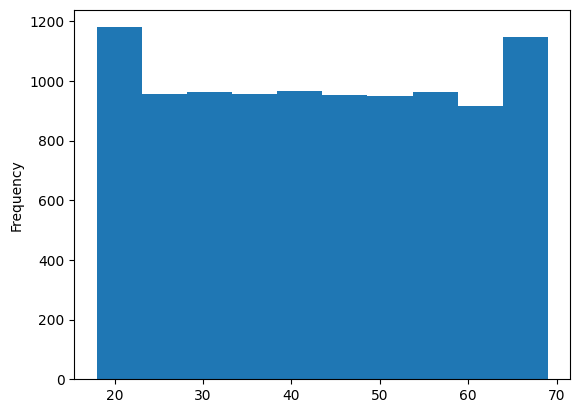

In [108]:
df.Customer_Age.plot(kind='hist')

In [109]:
clean.to_csv(
    "financial_sales_clean.csv",
    index=False
)

#FEATURE ENGINEERING

In [110]:
features = clean.copy()

In [111]:
# CREATING PROFITS PER UNIT FROM GROSS PROFIT AND UNIT COLUMN
features["Units_Sold"] = features["Units_Sold"].replace(0, np.nan) #TO AVOID ZERO DIVISION REPLACE UNITS SOLD WITH NULL
features["Revenue_Per_Unit"] =(features.Net_Sales_Before_Tax/features.Unit_Price)# Revenue per unit measures the average amount of money a business earns for every individual product or service unit sold
features["profit_per_unit"]=(features.Gross_Profit/features.Unit_Price)
features["Discount_Ratio"] = (
    features["Discount_Amount"] /
    features["Gross_Sales"]
)
features["Cost_Ratio"] = (
    features["Cost_of_Goods"] /
    features["Net_Sales_Before_Tax"]
)
features["Shipping_Ratio"] = (
    features["Shipping_Cost"] /
    features["Net_Sales_Before_Tax"]
)
features["Return_Rate"] = (
    features["Returns_Count"] /
    features["Units_Sold"]
)


In [112]:
features.Transaction_Date

,Transaction_Date
0,2025-04-13
1,2025-04-24
2,2025-10-16
3,2025-08-11
4,2025-08-28
...,...
10020,2025-06-08
10021,2025-02-19
10022,2025-11-13
10023,2025-10-29


In [113]:
features["Year"] = (
    features["Transaction_Date"].dt.year
)

features["Month_Number"] = (
    features["Transaction_Date"].dt.month
)

features["Month"] = (
    features["Transaction_Date"].dt.month_name()
)

features["Quarter"] = (
    features["Transaction_Date"].dt.quarter
)

features["Day"] = (
    features["Transaction_Date"].dt.day
)

features["Day_of_Week"] = (
    features["Transaction_Date"].dt.day_name()
)
features["Is_Weekend"] = (features["Transaction_Date"].dt.dayofweek>= 5)

In [114]:
features["Age_Group"] = pd.cut(
    features["Customer_Age"],
    bins=[0, 25, 35, 50, 65, 100],
    labels=[
        "18-25",
        "26-35",
        "36-50",
        "51-65",
        "66+"
    ]
)

In [115]:
features["Tenure_Group"] = pd.cut(
    features["Customer_Tenure_Months"],
    bins=[-1, 6, 12, 24, 48, 999],
    labels=[
        "0-6 Months",
        "7-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49+ Months"
    ]
)

In [116]:
features["Profitability"] = np.where(
    features["Gross_Profit"] > 0,
    "Profitable",
    "Loss"
)

In [117]:
features["High_Discount"] = np.where(
    features["Discount"] >= 20,
    "High Discount",
    "Normal Discount"
)

In [118]:
features["Delivery_Category"] = pd.cut(
    features["Delivery_Days"],
    bins=[0, 3, 7, 100],
    labels=[
        "Fast",
        "Standard",
        "Delayed"
    ]
)

#CUSTOMER LEVEL TABLE

In [119]:
customer_summary = (
    features
    .groupby("Customer_ID")
    .agg(
        Total_Sales=("End_Sales", "sum"),
        Total_Profit=("Gross_Profit", "sum"),
        Total_Orders=("Invoice_ID", "count"),
        Total_Units=("Units_Sold", "sum"),
        Average_Order_Value=("End_Sales", "mean"),
        Average_Discount=("Discount", "mean"),
        Average_Rating=("Customer_Rating", "mean"),
        Total_Returns=("Returns_Count", "sum")
    )
    .reset_index()
)

In [120]:
customer_summary.head()

,Customer_ID,Total_Sales,Total_Profit,Total_Orders,Total_Units,Average_Order_Value,Average_Discount,Average_Rating,Total_Returns
0,CUST-00001,80489.19,19951.93,4,20,20122.2975,7.0425,3.500,1
1,CUST-00002,12161.11,3282.77,4,9,3040.2775,8.0275,4.025,2
2,CUST-00003,34032.38,12525.34,1,15,34032.3800,11.8500,4.200,0
3,CUST-00004,6602.59,1734.28,2,6,3301.2950,6.3000,3.900,1
4,CUST-00005,6195.61,693.46,1,6,6195.6100,11.4000,3.900,1


In [121]:
customer_summary["Return_Rate"] = (customer_summary["Total_Returns"] /customer_summary["Total_Units"])
customer_summary["Return_Rate"] = (customer_summary["Return_Rate"].fillna(0))

In [122]:
customer_summary["Profit_Per_Order"] = (customer_summary["Total_Profit"] /customer_summary["Total_Orders"])

##GENERATE RFM

In [123]:
# Recency

# First establish the latest transaction date:
reference_date = features["Transaction_Date"].max()
# Then get each customer's last purchase:
last_purchase=(features.groupby("Customer_ID")["Transaction_Date"].max())
# Convert that into days:
recency = (reference_date - last_purchase).dt.days
# Turn it into a dataframe:
recency1 = recency.reset_index(name="Recency_Days")
rfm = customer_summary.merge( recency1, on="Customer_ID")
rfm.head()

,Customer_ID,Total_Sales,Total_Profit,Total_Orders,Total_Units,Average_Order_Value,Average_Discount,Average_Rating,Total_Returns,Return_Rate,Profit_Per_Order,Recency_Days
0,CUST-00001,80489.19,19951.93,4,20,20122.2975,7.0425,3.500,1,0.050000,4987.9825,16.0
1,CUST-00002,12161.11,3282.77,4,9,3040.2775,8.0275,4.025,2,0.222222,820.6925,64.0
2,CUST-00003,34032.38,12525.34,1,15,34032.3800,11.8500,4.200,0,0.000000,12525.3400,355.0
3,CUST-00004,6602.59,1734.28,2,6,3301.2950,6.3000,3.900,1,0.166667,867.1400,24.0
4,CUST-00005,6195.61,693.46,1,6,6195.6100,11.4000,3.900,1,0.166667,693.4600,126.0


In [124]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency_Days"],
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Total_Orders"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_Score"] = pd.qcut(
    rfm["Total_Sales"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

In [125]:
rfm.dropna(inplace=True)

In [126]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(int).astype(str) +
    rfm["F_Score"].astype(int).astype(str) +
    rfm["M_Score"].astype(int).astype(str)
)

In [127]:
rfm.sort_values(
    "Total_Sales",
    ascending=False
).head(20)

,Customer_ID,Total_Sales,Total_Profit,Total_Orders,Total_Units,Average_Order_Value,Average_Discount,Average_Rating,Total_Returns,Return_Rate,Profit_Per_Order,Recency_Days,R_Score,F_Score,M_Score,RFM_Score
72,CUST-00076,178433.52,54066.57,5,57,35686.704000,11.296000,4.200000,3,0.052632,10813.314000,3.0,5,5,5,555
115,CUST-00119,168829.91,54602.21,2,28,84414.955000,6.180000,3.600000,0,0.000000,27301.105000,19.0,5,1,5,515
1329,CUST-01398,157217.79,53448.41,1,20,157217.790000,4.950000,4.400000,0,0.000000,53448.410000,141.0,2,1,5,215
1503,CUST-01586,156924.25,57531.32,3,18,52308.083333,9.490000,4.133333,1,0.055556,19177.106667,60.0,4,3,5,435
419,CUST-00439,151025.88,41970.45,9,48,16780.653333,9.732222,3.777778,2,0.041667,4663.383333,33.0,4,5,5,455
3161,CUST-03353,149289.16,32815.16,3,26,49763.053333,14.243333,4.366667,0,0.000000,10938.386667,19.0,5,4,5,545
452,CUST-00472,146576.96,42237.11,4,36,36644.240000,2.020000,4.075000,2,0.055556,10559.277500,19.0,5,4,5,545
1714,CUST-01811,142850.64,39360.52,4,35,35712.660000,4.722500,3.700000,2,0.057143,9840.130000,72.0,3,4,5,345
3216,CUST-03410,139798.56,39648.05,6,38,23299.760000,7.186667,4.250000,3,0.078947,6608.008333,16.0,5,5,5,555
2237,CUST-02366,138087.33,26302.77,2,22,69043.665000,6.365000,4.100000,0,0.000000,13151.385000,10.0,5,2,5,525


In [128]:
monthly_sales = features.groupby(["Month_Number", "Month"])["End_Sales"].sum().reset_index().sort_values("Month_Number")


print(monthly_sales)

    Month_Number      Month   End_Sales
0            1.0    January  6857305.84
1            2.0   February  6416240.45
2            3.0      March  7229746.41
3            4.0      April  7081164.55
4            5.0        May  7394358.29
5            6.0       June  7140502.44
6            7.0       July  7011514.92
7            8.0     August  7808788.46
8            9.0  September  6575666.49
9           10.0    October  7267855.77
10          11.0   November  7476974.93
11          12.0   December  7285005.05


<Axes: xlabel='Month'>

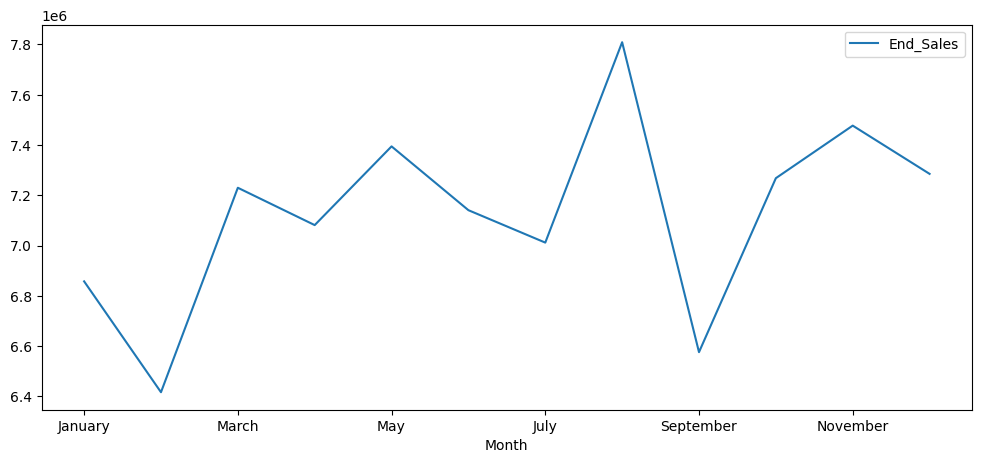

In [129]:
monthly_sales.plot(
    x="Month",
    y="End_Sales",
    kind="line",
    figsize=(12,5)
)

In [130]:
category_analysis = (
    features
    .groupby("Product_Category")
    .agg(
        Sales=("End_Sales", "sum"),
        Profit=("Gross_Profit", "sum"),
        Units=("Units_Sold", "sum"),
        Average_Discount=("Discount", "mean"),
        Return_Rate=("Return_Rate", "mean")
    )
    .reset_index()
)

In [131]:
category_analysis.sort_values(
    "Sales",
    ascending=False
)


,Product_Category,Sales,Profit,Units,Average_Discount,Return_Rate
2,Electronics,19193313.49,5177471.69,9536,7.386127,0.127749
1,Clothing,16989518.29,4699852.01,8207,7.713388,0.152518
4,Home Appliances,14234968.86,3953640.40,6954,7.561795,0.136632
3,Furniture,13019884.28,3532133.58,6385,7.530502,0.132394
5,Office Supplies,12189352.55,3390250.63,6218,7.498799,0.135954
0,Accessories,10949640.51,2963707.30,5177,7.365749,0.136904


In [132]:
category_analysis.sort_values(
    "Profit",
    ascending=False
)

,Product_Category,Sales,Profit,Units,Average_Discount,Return_Rate
2,Electronics,19193313.49,5177471.69,9536,7.386127,0.127749
1,Clothing,16989518.29,4699852.01,8207,7.713388,0.152518
4,Home Appliances,14234968.86,3953640.40,6954,7.561795,0.136632
3,Furniture,13019884.28,3532133.58,6385,7.530502,0.132394
5,Office Supplies,12189352.55,3390250.63,6218,7.498799,0.135954
0,Accessories,10949640.51,2963707.30,5177,7.365749,0.136904


In [133]:
features.columns

Index(['Invoice_ID', 'Transaction_Date', 'Customer_ID', 'Region', 'City',
       'Sales_Channel', 'Customer_Type', 'Product_Category', 'Payment_Method',
       'Salesperson_ID', 'Units_Sold', 'Unit_Price', 'Discount',
       'Shipping_Cost', 'Tax_Rate', 'Gross_Sales', 'Discount_Amount',
       'Net_Sales_Before_Tax', 'Tax_Amount', 'Total_Invoice_Value',
       'Cost_of_Goods', 'Gross_Profit', 'Profit_Margin_Pct', 'Customer_Age',
       'Customer_Tenure_Months', 'Orders_Last_90_Days', 'Returns_Count',
       'Delivery_Days', 'Customer_Rating', 'Late_Payment', 'End_Sales',
       'Revenue_Per_Unit', 'profit_per_unit', 'Discount_Ratio', 'Cost_Ratio',
       'Shipping_Ratio', 'Return_Rate', 'Year', 'Month_Number', 'Month',
       'Quarter', 'Day', 'Day_of_Week', 'Is_Weekend', 'Age_Group',
       'Tenure_Group', 'Profitability', 'High_Discount', 'Delivery_Category'],
      dtype='object')

In [134]:
region_analysis = (
    features
    .groupby("Region")
    .agg(
        Sales=("End_Sales", "sum"),
        Profit=("Gross_Profit", "sum"),
        Orders=("Invoice_ID", "count"),
        Average_Order_Value=("End_Sales", "mean"),
        Margin=("Profit_Margin_Pct", "mean"),
        Return_Rate=("Return_Rate", "mean")
    )
    .reset_index()
)

In [135]:
region_analysis.sort_values(
    "Profit",
    ascending=False
)

,Region,Sales,Profit,Orders,Average_Order_Value,Margin,Return_Rate
4,South,17208418.67,4824791.20,1992,8638.764393,33.291330,0.134789
5,West,15871682.09,4270028.21,1748,9079.909662,32.642059,0.134535
1,East,14687109.92,4074744.23,1752,8383.053607,33.421467,0.143636
2,North,14576309.66,4039148.70,1762,8272.593451,33.408706,0.138578
0,Central,12736257.02,3444102.31,1453,8765.490034,32.464501,0.136912
3,Northeast,10476932.77,2774988.28,1173,8931.741492,32.783743,0.134953


##DOES DISCOUNTING CORRELATES WITH SALES

In [136]:
features[
    [
        "Discount",
        "End_Sales",
        "Gross_Profit",
        "Profit_Margin_Pct"
    ]
].corr(numeric_only=True)

,Discount,End_Sales,Gross_Profit,Profit_Margin_Pct
Discount,1.000000,-0.024827,-0.026297,-0.005696
End_Sales,-0.024827,1.000000,0.930935,-0.005348
Gross_Profit,-0.026297,0.930935,1.000000,0.207884
Profit_Margin_Pct,-0.005696,-0.005348,0.207884,1.000000


In [137]:
#its nothing but calculating percentage of profit
category_analysis["Profit_Margin"] = (
    category_analysis["Profit"] / category_analysis["Sales"] * 100
)

In [138]:
category_analysis = category_analysis.sort_values(
    "Profit", ascending=False
)

category_analysis

,Product_Category,Sales,Profit,Units,Average_Discount,Return_Rate,Profit_Margin
2,Electronics,19193313.49,5177471.69,9536,7.386127,0.127749,26.975393
1,Clothing,16989518.29,4699852.01,8207,7.713388,0.152518,27.663245
4,Home Appliances,14234968.86,3953640.40,6954,7.561795,0.136632,27.774142
3,Furniture,13019884.28,3532133.58,6385,7.530502,0.132394,27.128763
5,Office Supplies,12189352.55,3390250.63,6218,7.498799,0.135954,27.813213
0,Accessories,10949640.51,2963707.30,5177,7.365749,0.136904,27.066709


In [139]:
category_analysis.sort_values(
    "Profit_Margin"
)

,Product_Category,Sales,Profit,Units,Average_Discount,Return_Rate,Profit_Margin
2,Electronics,19193313.49,5177471.69,9536,7.386127,0.127749,26.975393
0,Accessories,10949640.51,2963707.30,5177,7.365749,0.136904,27.066709
3,Furniture,13019884.28,3532133.58,6385,7.530502,0.132394,27.128763
1,Clothing,16989518.29,4699852.01,8207,7.713388,0.152518,27.663245
4,Home Appliances,14234968.86,3953640.40,6954,7.561795,0.136632,27.774142
5,Office Supplies,12189352.55,3390250.63,6218,7.498799,0.135954,27.813213


##The question:

##Does giving bigger discounts actually improve business performance?

In [140]:
features["Discount_Band"] = pd.cut(
    features["Discount"],
    bins=[-1, 5, 10, 20, 30, 100],
    labels=[
        "0-5%",
        "6-10%",
        "11-20%",
        "21-30%",
        "31%+"
    ]
)

In [141]:
discount_analysis = (
    features.groupby("Discount_Band", observed=True)
    .agg(
        Orders=("Invoice_ID", "count"),
        Sales=("End_Sales", "sum"),
        Average_Sales=("End_Sales", "mean"),
        Profit=("Gross_Profit", "sum"),
        Average_Profit=("Gross_Profit", "mean"),
        Average_Margin=("Profit_Margin_Pct", "mean")
    )
    .reset_index()
)

discount_analysis

,Discount_Band,Orders,Sales,Average_Sales,Profit,Average_Profit,Average_Margin
0,0-5%,3469,30465195.51,8782.126120,8453261.28,2436.800600,33.201807
1,6-10%,3905,34288673.23,8780.710174,9336427.05,2390.890410,32.885483
2,11-20%,2477,20744714.38,8374.935155,5621521.37,2269.487836,33.028187
3,21-30%,149,1078094.86,7235.535973,305845.91,2052.657114,33.363423


##Which categories are most sensitive to discounting?

In [142]:
discount_category = (
    features.groupby(
        ["Product_Category", "Discount_Band"],
        observed=True
    )
    .agg(
        Orders=("Invoice_ID", "count"),
        Sales=("End_Sales", "sum"),
        Profit=("Gross_Profit", "sum"),
        Margin=("Profit_Margin_Pct", "mean")
    )
    .reset_index()
)

discount_category

,Product_Category,Discount_Band,Orders,Sales,Profit,Margin
0,Accessories,0-5%,439,4187799.80,1143668.17,32.690524
1,Accessories,6-10%,458,4084439.27,1082483.92,32.449847
2,Accessories,11-20%,299,2571455.18,704571.36,33.218328
3,Accessories,21-30%,13,105946.26,32983.85,38.600000
4,Clothing,0-5%,643,5571210.04,1543403.73,32.839098
5,Clothing,6-10%,770,7061568.69,1934527.54,32.826299
6,Clothing,11-20%,484,4167206.47,1166068.80,33.796012
7,Clothing,21-30%,39,189533.09,55851.94,35.277949
8,Electronics,0-5%,792,6793191.97,1889216.64,33.521591
9,Electronics,6-10%,881,7832233.38,2072767.04,32.619126


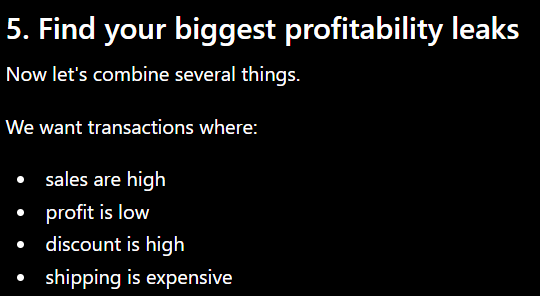

In [143]:
features["Profit_Margin_Calc"] = (
    features["Gross_Profit"] /
    features["End_Sales"] * 100
)

leakage = features[
    (features["End_Sales"] > features["End_Sales"].median()) &
    (features["Profit_Margin_Calc"] < features["Profit_Margin_Calc"].median()) &
    (features["Discount"] > features["Discount"].median())
]



In [144]:
leakage[
    [
        "Invoice_ID",
        "Product_Category",
        "Region",
        "Discount",
        "Shipping_Cost",
        "End_Sales",
        "Gross_Profit",
        "Profit_Margin_Calc"
    ]
].head(20).sort_values("Profit_Margin_Calc",ascending=False)

,Invoice_ID,Product_Category,Region,Discount,Shipping_Cost,End_Sales,Gross_Profit,Profit_Margin_Calc
125,INV-2025-008305,Accessories,West,14.87,223.93,15311.64,3935.70,25.703974
65,INV-2025-001132,Clothing,West,14.53,972.39,9399.55,2371.57,25.230676
26,INV-2025-004832,Office Supplies,North,12.75,554.59,6235.67,1568.56,25.154635
127,INV-2025-000276,Electronics,East,16.47,348.96,6492.88,1615.72,24.884489
121,INV-2025-008399,Electronics,East,7.09,40.00,23467.33,5831.58,24.849781
59,INV-2025-000494,Furniture,South,9.49,305.41,9936.20,2453.04,24.687909
34,INV-2025-003092,Furniture,Central,8.94,520.29,6957.45,1685.68,24.228417
25,INV-2025-008882,Home Appliances,West,10.80,176.68,6516.51,1496.86,22.970271
137,INV-2025-009828,Furniture,East,8.46,294.35,15422.57,3499.34,22.689733
2,INV-2025-004226,Furniture,South,9.49,139.38,8330.68,1888.78,22.672579


In [145]:
customer_sales = (
    features.groupby("Customer_ID")["End_Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

customer_sales["Cumulative_Sales"] = (
    customer_sales["End_Sales"].cumsum()
)

total_sales = customer_sales["End_Sales"].sum()

customer_sales["Cumulative_Percentage"] = (
    customer_sales["Cumulative_Sales"]
    / total_sales * 100
)

customer_sales.head(20)

,Customer_ID,End_Sales,Cumulative_Sales,Cumulative_Percentage
0,CUST-00076,178433.52,178433.52,0.206099
1,CUST-00119,168829.91,347263.43,0.401105
2,CUST-01398,157217.79,504481.22,0.582699
3,CUST-01586,156924.25,661405.47,0.763953
4,CUST-00439,151025.88,812431.35,0.938395
5,CUST-03353,149289.16,961720.51,1.110831
6,CUST-00472,146576.96,1108297.47,1.280134
7,CUST-01811,142850.64,1251148.11,1.445133
8,CUST-03410,139798.56,1390946.67,1.606607
9,CUST-02366,138087.33,1529034.00,1.766104


#Pareto analysis
#find how much of the company's sales come from the top 10% of customers:

In [146]:
top_10_percent = int(len(customer_sales) * 0.10)

top_10_sales = customer_sales.head(top_10_percent)["End_Sales"].sum()

top_10_contribution = (
    top_10_sales / total_sales * 100
)

print(top_10_contribution)

30.23807033349976


In [147]:
rfm["Customer_Segment"] = "Regular"

rfm.loc[
    (rfm["R_Score"] >= 4) &
    (rfm["F_Score"] >= 4) &
    (rfm["M_Score"] >= 4),
    "Customer_Segment"
] = "High Value"

rfm.loc[
    (rfm["R_Score"] <= 2) &
    (rfm["F_Score"] >= 4),
    "Customer_Segment"
] = "At Risk"

rfm.loc[
    (rfm["R_Score"] >= 4) &
    (rfm["F_Score"] <= 2),
    "Customer_Segment"
] = "New/Potential"

rfm["Customer_Segment"].value_counts()

,count
Customer_Segment,
At Risk,1241
New/Potential,1148
Regular,859
High Value,52


In [148]:
segment_analysis = (
    rfm.groupby("Customer_Segment")
    .agg(
        Customers=("Customer_ID", "count"),
        Sales=("Total_Sales", "sum"),
        Profit=("Total_Profit", "sum"),
        Orders=("Total_Orders", "sum"),
        Average_Order_Value=("Average_Order_Value", "mean")
    )
    .reset_index()
)

segment_analysis

,Customer_Segment,Customers,Sales,Profit,Orders,Average_Order_Value
0,At Risk,1241,49632830.76,13635240.98,5742,8652.574056
1,High Value,52,2552956.30,661427.88,221,12161.368631
2,New/Potential,1148,15313534.52,4143287.77,1759,8762.329456
3,Regular,859,19017490.42,5256483.01,2273,8378.980115


#Does a higher discount tend to be associated with lower profit?

In [149]:
features[[
    "Discount",
    "End_Sales",
    "Gross_Profit",
    "Profit_Margin_Pct",
    "Units_Sold",
    "Shipping_Cost",
    "Customer_Rating"
]].corr()

,Discount,End_Sales,Gross_Profit,Profit_Margin_Pct,Units_Sold,Shipping_Cost,Customer_Rating
Discount,1.000000,-0.024827,-0.026297,-0.005696,0.016978,-0.010406,0.011516
End_Sales,-0.024827,1.000000,0.930935,-0.005348,0.660742,0.016016,0.011834
Gross_Profit,-0.026297,0.930935,1.000000,0.207884,0.622586,-0.005411,0.011685
Profit_Margin_Pct,-0.005696,-0.005348,0.207884,1.000000,-0.000697,-0.004412,0.001350
Units_Sold,0.016978,0.660742,0.622586,-0.000697,1.000000,0.011029,0.007428
Shipping_Cost,-0.010406,0.016016,-0.005411,-0.004412,0.011029,1.000000,-0.013707
Customer_Rating,0.011516,0.011834,0.011685,0.001350,0.007428,-0.013707,1.000000


#Do high-discount transactions have different profit margins than normal-discount transactions?

In [150]:
features.groupby("High_Discount")["Profit_Margin_Pct"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
High_Discount,,,,
High Discount,150,33.338133,32.985,10.142091
Normal Discount,9850,33.033110,33.040,9.968746


#but even with this we have a question
Is that difference large enough that we have evidence it isn't simply sampling variation?

That's where a hypothesis test comes in.

Null hypothesis — H₀

There is no difference in average profit margin between the two groups.

Alternative hypothesis — H₁

There is a difference in average profit margin between the two groups.

We're going to use a t-test because we're comparing the means of two groups.

In [151]:
from scipy.stats import ttest_ind #independent t test

high_discount = features[
    features["High_Discount"] == "High Discount"
]["Profit_Margin_Pct"]

normal_discount = features[
    features["High_Discount"] == "Normal Discount"
]["Profit_Margin_Pct"]

In [152]:
high_discount

,Profit_Margin_Pct
185,27.61
187,51.13
237,51.74
248,57.04
277,60.00
...,...
9673,30.25
9843,38.95
9856,22.18
9918,42.16


In [153]:
t_stat, p_value = ttest_ind(
    high_discount,
    normal_discount,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 0.36566234298678446
P-value: 0.715120734908107


In [154]:
mean_high = high_discount.mean()
mean_normal = normal_discount.mean()

difference = mean_normal - mean_high

print("Mean difference:", difference)

Mean difference: -0.3050236886632831


ANOVA

A t-test works when we have two groups.

But suppose we ask:

Does average sales differ across product categories?

In [155]:
features.groupby("Product_Category")["End_Sales"].mean()

,End_Sales
Product_Category,
Accessories,9056.774615
Clothing,8775.577629
Electronics,8614.593128
Furniture,8487.538644
Home Appliances,8749.212575
Office Supplies,8314.701603


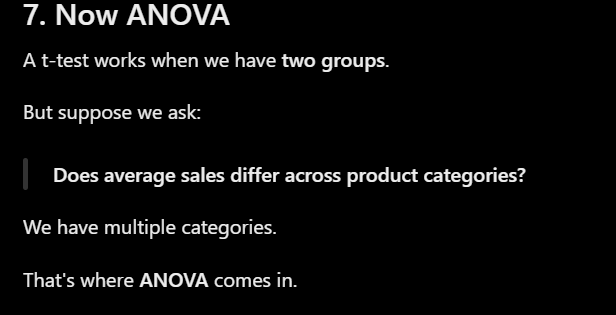

In [156]:
from scipy.stats import f_oneway

groups = []

for category in features["Product_Category"].dropna().unique():

    group = features[
        features["Product_Category"] == category
    ]["End_Sales"]

    groups.append(group)

In [157]:
f_stat, p_value = f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 0.7863525284034986
P-value: 0.5593083850675667


#If ANOVA is significant, we can perform a post-hoc test.
One common choice is Tukey's HSD.

In [158]:
!pip install statsmodels
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=features["End_Sales"],
    groups=features["Product_Category"],
    alpha=0.05
)

print(tukey)

            Multiple Comparison of Means - Tukey HSD, FWER=0.05             
     group1          group2      meandiff p-adj    lower      upper   reject
----------------------------------------------------------------------------
    Accessories        Clothing  -281.197 0.9803 -1404.0206  841.6266  False
    Accessories     Electronics -442.1815 0.8595 -1536.3546  651.9917  False
    Accessories       Furniture  -569.236 0.7408 -1747.2599  608.7879  False
    Accessories Home Appliances  -307.562  0.975 -1470.6518  855.5277  False
    Accessories Office Supplies  -742.073 0.4805  -1932.078   447.932  False
       Clothing     Electronics -160.9845 0.9968 -1112.7109  790.7419  False
       Clothing       Furniture  -288.039 0.9703 -1335.0865  759.0086  False
       Clothing Home Appliances  -26.3651    1.0 -1056.5815 1003.8514  False
       Clothing Office Supplies  -460.876 0.8178 -1521.3854  599.6334  False
    Electronics       Furniture -127.0545 0.9992 -1143.3176  889.2086  False

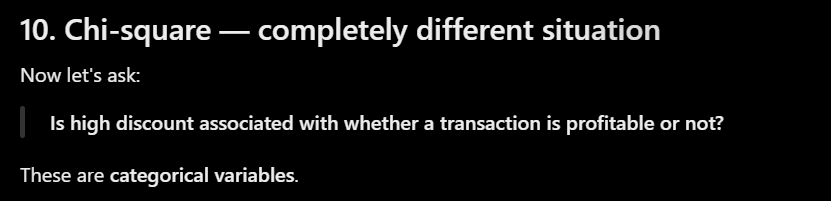

In [159]:
pd.crosstab(
    features["High_Discount"],
    features["Profitability"]
)

Profitability,Profitable
High_Discount,
High Discount,150
Normal Discount,9850


In [160]:
from scipy.stats import chi2_contingency

table = pd.crosstab(
    features["High_Discount"],
    features["Profitability"]
)

chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("P-value:", p_value)

Chi-square: 0.0
P-value: 1.0


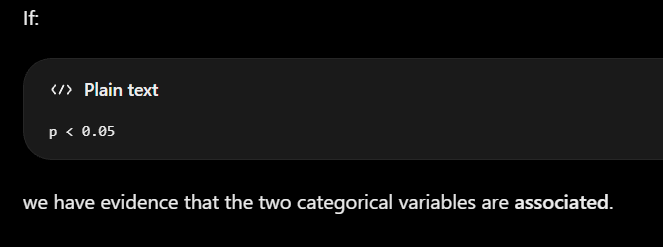

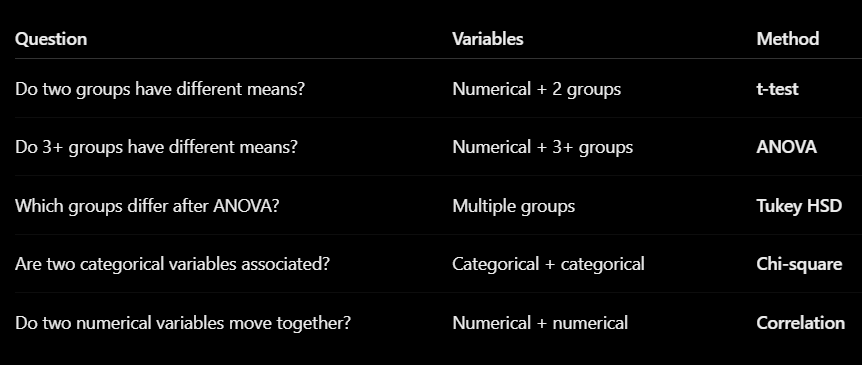

In [161]:
# Check how closely the final sales value matches
# the invoice value calculated from the transaction.

comparison = features[
    ["End_Sales", "Total_Invoice_Value"]
].copy()

comparison["Difference"] = (
    comparison["End_Sales"]
    - comparison["Total_Invoice_Value"]
)

print("Rows with different values:")
print((comparison["Difference"].abs() > 0.01).sum())

print("\nSample differences:")
print(comparison[comparison["Difference"].abs() > 0.01].head(10))

Rows with different values:
50

Sample differences:
      End_Sales  Total_Invoice_Value  Difference
351    17925.71             32032.79   -14107.08
715     2696.71              8512.78    -5816.07
794     6955.12             19396.27   -12441.15
868     3541.55              9600.73    -6059.18
1588     902.81              1209.76     -306.95
1695    1476.71              4268.45    -2791.74
1752    1116.03              1757.98     -641.95
1829    5128.73              7879.35    -2750.62
2307    2451.14              3281.66     -830.52
2366    1066.36              1438.46     -372.10


In [162]:
model_data = features[
    [
        "End_Sales",
        "Units_Sold",
        "Unit_Price",
        "Discount",
        "Region",
        "City",
        "Sales_Channel",
        "Customer_Type",
        "Product_Category",
        "Customer_Age",
        "Customer_Tenure_Months",
        "Orders_Last_90_Days"
    ]
].copy()

model_data = model_data.dropna()

print("Model dataset shape:", model_data.shape)



Model dataset shape: (9880, 12)


In [163]:
model_data.head()

,End_Sales,Units_Sold,Unit_Price,Discount,Region,City,Sales_Channel,Customer_Type,Product_Category,Customer_Age,Customer_Tenure_Months,Orders_Last_90_Days
0,3117.38,6,566.02,10.56,South,Chennai,Retail Store,Returning,Furniture,44.0,32.0,3
1,7991.26,6,1132.34,2.97,North,Chandigarh,Online,Returning,Accessories,38.0,30.0,2
2,8330.68,3,3016.72,9.49,South,Kochi,Corporate,Returning,Furniture,46.0,8.0,1
3,20746.18,6,2920.60,1.10,Northeast,Imphal,Distributor,Vip,Electronics,46.0,3.0,2
4,49437.36,10,4596.32,9.02,Central,Raipur,Distributor,New,Furniture,18.0,12.0,1


In [164]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Separate inputs (X) and target (y)
X = model_data.drop(columns=["End_Sales"])
y = model_data["End_Sales"]

# 2. Identify numerical and categorical columns
numeric_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(exclude="number").columns.tolist()

# 3. Prepare numerical and categorical inputs
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numbers", numeric_pipeline, numeric_columns),
    ("categories", categorical_pipeline, categorical_columns)
])

# 4. Create the complete model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# 5. Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

# 6. Train the model
model.fit(X_train, y_train)

# 7. Predict sales for unseen test rows
predictions = model.predict(X_test)

# 8. Evaluate predictions
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("\nMODEL PERFORMANCE")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 4))

# 9. Compare actual and predicted values
results = pd.DataFrame({
    "Actual_Sales": y_test.values,
    "Predicted_Sales": predictions
})

results["Absolute_Error"] = (
    results["Actual_Sales"] - results["Predicted_Sales"]
).abs()

print("\nSample predictions:")
print(results.head(10).round(2))


Training rows: 7904
Testing rows: 1976

MODEL PERFORMANCE
MAE: 2495.32
RMSE: 5067.85
R²: 0.7486

Sample predictions:
   Actual_Sales  Predicted_Sales  Absolute_Error
0       1868.52          1288.57          579.95
1       2251.76          1606.58          645.18
2       4547.00          5535.05          988.05
3       7885.38          7399.12          486.26
4       3904.72          3703.53          201.19
5       6969.33         11940.65         4971.32
6       1669.48          1614.92           54.56
7       2286.37          1073.42         1212.95
8      24364.17         21951.60         2412.57
9       5615.97          5697.84           81.87


In [165]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Build Random Forest model
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
rf_model.fit(X_train, y_train)

# Predict
rf_predictions = rf_model.predict(X_test)

# Evaluate
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST PERFORMANCE")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R²:", round(rf_r2, 4))

# Compare both models
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2": [r2, rf_r2]
})

print("\nMODEL COMPARISON")
print(comparison.round(4))


RANDOM FOREST PERFORMANCE
MAE: 702.79
RMSE: 2393.98
R²: 0.9439

MODEL COMPARISON
               Model        MAE       RMSE      R2
0  Linear Regression  2495.3239  5067.8482  0.7486
1      Random Forest   702.7912  2393.9819  0.9439


In [166]:

# Inspect the Random Forest's prediction errors

results = pd.DataFrame({
    "Actual_Sales": y_test,
    "Predicted_Sales": rf_predictions
})

results["Error"] = (
    results["Actual_Sales"] - results["Predicted_Sales"]
)

results["Absolute_Error"] = results["Error"].abs()

print("Error summary:")
print(results["Error"].describe().round(2))

print("\nLargest prediction errors:")
print(
    results.sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(2)
)

# Compare actual and predicted averages
print("\nActual mean:", round(y_test.mean(), 2))
print("Predicted mean:", round(rf_predictions.mean(), 2))


Error summary:
count     1976.00
mean         7.91
std       2394.57
min     -52127.93
25%       -284.88
50%        -17.36
75%        312.45
max      36557.03
Name: Error, dtype: float64

Largest prediction errors:
      Actual_Sales  Predicted_Sales     Error  Absolute_Error
9435      12134.17         64262.10 -52127.93        52127.93
7332      65729.90         29172.87  36557.03        36557.03
6278       4270.95         40108.90 -35837.95        35837.95
7140      66286.22         31504.11  34782.11        34782.11
3971     118448.11         90016.85  28431.26        28431.26
1596     137114.50        110204.62  26909.88        26909.88
7709       4547.79         30516.84 -25969.05        25969.05
351       17925.71         30358.50 -12432.79        12432.79
5946      69825.54         57977.39  11848.15        11848.15
4789      79628.21         68647.27  10980.94        10980.94

Actual mean: 8436.63
Predicted mean: 8428.72


In [167]:

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Prepare the dataset
columns = [
    "Units_Sold",
    "Unit_Price",
    "Discount",
    "Region",
    "City",
    "Sales_Channel",
    "Customer_Type",
    "Product_Category",
    "Customer_Age",
    "Customer_Tenure_Months",
    "Orders_Last_90_Days"
]

model_data = features[
    columns + ["End_Sales", "Transaction_Date"]
].copy()

model_data["Transaction_Date"] = pd.to_datetime(
    model_data["Transaction_Date"], errors="coerce"
)

# Remove rows without a valid target or date
model_data = model_data.dropna(
    subset=["Transaction_Date", "End_Sales"]
)

# 2. Strict chronological split: train before Oct 19
cutoff_date = pd.Timestamp("2025-10-19")

train_data = model_data[
    model_data["Transaction_Date"] < cutoff_date
].copy()

test_data = model_data[
    model_data["Transaction_Date"] >= cutoff_date
].copy()

X_train = train_data[columns].copy()
y_train = train_data["End_Sales"]

X_test = test_data[columns].copy()
y_test = test_data["End_Sales"]

# Convert pandas nullable values to standard NumPy missing values
for col in columns:
    if X_train[col].dtype == "object" or \
       isinstance(X_train[col].dtype, pd.StringDtype):
        X_train[col] = X_train[col].astype(object).where(
            X_train[col].notna(), np.nan
        )
        X_test[col] = X_test[col].astype(object).where(
            X_test[col].notna(), np.nan
        )

# Identify column types after conversion
numeric_columns = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

# 3. Preprocessing
preprocessor = ColumnTransformer([
    ("numbers", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), numeric_columns),

    ("categories", Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_columns)
])

# 4. Compare models on the same chronological holdout
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", estimator)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

    if name == "Random Forest":
        error_results = pd.DataFrame({
            "Transaction_Date": test_data["Transaction_Date"].values,
            "Actual_Sales": y_test.values,
            "Predicted_Sales": predictions
        })

        error_results["Absolute_Error"] = (
            error_results["Actual_Sales"]
            - error_results["Predicted_Sales"]
        ).abs()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training ends:", train_data["Transaction_Date"].max())
print("Testing begins:", test_data["Transaction_Date"].min())

print("\nCHRONOLOGICAL TEST RESULTS")
print(pd.DataFrame(results).round(3).to_string(index=False))

print("\nLARGEST RANDOM FOREST ERRORS")
print(
    error_results.sort_values(
        "Absolute_Error", ascending=False
    ).head(10).round(2).to_string(index=False)
)

# Save evaluation results
pd.DataFrame(results).to_csv(
    "sales_model_comparison.csv", index=False
)

error_results.to_csv(
    "sales_prediction_test_results.csv", index=False
)


Training rows: 7898
Testing rows: 1982
Training ends: 2025-10-18 00:00:00
Testing begins: 2025-10-19 00:00:00

CHRONOLOGICAL TEST RESULTS
            Model      MAE     RMSE    R2
Linear Regression 2655.326 5669.502 0.706
    Random Forest  651.607 1799.147 0.970

LARGEST RANDOM FOREST ERRORS
Transaction_Date  Actual_Sales  Predicted_Sales  Absolute_Error
      2025-10-23       8618.32         57401.08        48782.76
      2025-10-23     120785.65         93781.87        27003.78
      2025-12-21     133847.95        116557.51        17290.44
      2025-12-21      91066.71         73930.27        17136.44
      2025-11-13      41824.17         29032.61        12791.56
      2025-12-16      38609.45         26587.24        12022.21
      2025-12-02       4245.40         13449.38         9203.98
      2025-11-12       1996.44         11042.50         9046.06
      2025-12-14      69422.70         60569.66         8853.04
      2025-11-11       2288.76         11011.29         8722.53


# SO RANDOM FOREST IS GIVING US THE BEST RESULTS

# DOWNLOADING THE CSV

In [170]:
# features.to_csv("financial_sales_features.csv", index=False)

rfm.to_csv("customer_rfm.csv", index=False)

In [169]:
rfm.groupby("R_Score")["Recency_Days"].mean()

/tmp/ipykernel_13363/2552966850.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rfm.groupby("R_Score")["Recency_Days"].mean()


,Recency_Days
R_Score,
5,12.974398
4,43.643939
3,83.490937
2,142.593893
1,252.789074
